# Solutions to the exercises of Chapter 6

Sample solutions for [Chapter 6, Semi-infinite solids and phase change](../../notebooks/part1_conduction/06_semi_infinite.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq
from scipy.special import erfinv

try:
    from engtransport import reference, transient
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference, transient
from engtransport.plotting import panel_label, use_style

use_style()
DAY, YEAR = 86400.0, 365.25 * 86400.0

# the soil of Section 6.4
rho_dry, w = 1600.0, 0.15
k_u, k_f = 1.5, 2.0
C_u, C_f = rho_dry * (800.0 + w * 4190.0), rho_dry * (800.0 + w * 2100.0)
L_v = rho_dry * w * 334e3

## Exercise 1. How long until it hurts?

While both bodies are semi-infinite, the skin surface stays at the contact temperature
$T_c$, and inside the skin the temperature is Eq. (6.1) with $T_s = T_c$:
$(T - T_c)/(T_{\rm skin} - T_c) = \mathrm{erf}(x/2\sqrt{\alpha t})$. Setting $T = 15$ °C at
$x = 1$ mm and inverting the error function gives the time.

In [2]:
skin_k, skin_rc, T_skin = 0.37, 3.5e6, 34.0
alpha_skin = skin_k / skin_rc
for name, k, rc in (("steel", 45.0, 7850 * 470.0), ("aluminium", 200.0, 2700 * 900.0), ("ice", 2.2, 917 * 2100.0)):
    T_c = transient.contact_temperature(skin_k, skin_rc, T_skin, k, rc, -30.0)
    eta = erfinv((15.0 - T_c) / (T_skin - T_c))
    t = (1e-3 / (2 * eta)) ** 2 / alpha_skin
    print(f"{name:9s}: contact {T_c:6.1f} C, skin 1 mm deep at 15 C after {t:4.1f} s")

steel    : contact  -24.8 C, skin 1 mm deep at 15 C after  4.8 s
aluminium: contact  -26.9 C, skin 1 mm deep at 15 C after  4.6 s
ice      : contact   -7.2 C, skin 1 mm deep at 15 C after  8.7 s


The nerves 1 mm deep reach 15 °C after about 5 s on steel and slightly sooner on
aluminium; on ice it takes 9 s. The surface of the skin is far colder than 15 °C from
the first instant, which is why the pain of touching cold metal comes so fast. The skin
is only 1–2 mm thick over living tissue with blood flow, so after several seconds the
semi-infinite model of the skin is no longer exact, but by then the damage is done.

## Exercise 2. Snow on the road

With the snow, the cold reaches the frozen soil through two resistances in series: the
snow, $R''_{\rm snow}$, and the frozen layer, $X/k_f$. If the latent heat dominates, the
heat flux $(T_f - T_s)/(R''_{\rm snow} + X/k_f)$ equals $L_v\,dX/dt$. Separating and
integrating from $X = 0$ gives

$$
\frac{X^2}{2k_f} + R''_{\rm snow} X = \frac{(T_f - T_s)\,t}{L_v} .
$$

In [3]:
season, T_s, T_i = 176 * DAY, -10.0, 5.0
R_snow = 0.30 / 0.2
rhs = (0.0 - T_s) * season / L_v
X_formula = k_f * (-R_snow + math.sqrt(R_snow**2 + 2 * rhs / k_f))
dx = 0.02
faces = np.arange(0.0, 10.3 + dx / 2, dx)
xc = 0.5 * (faces[1:] + faces[:-1])
snow = xc < 0.30
out = reference.enthalpy_1d_fv(faces, np.where(snow, 0.2, k_f), np.where(snow, 300 * 2100.0, C_f),
                               np.where(snow, 0.2, k_u), np.where(snow, 300 * 2100.0, C_u), np.where(snow, 0.0, L_v),
                               0.0, np.where(snow, -5.0, T_i), season, left=("temperature", T_s),
                               right=("temperature", T_i), t_save=np.linspace(0, season, 89))
X_fv = out["front"] - 0.30                                 # the snow is frozen but is not soil
no_snow = transient.neumann_freezing(k_f, C_f, k_u, C_u, L_v, T_s, 0.0, T_i)
print(f"snow resistance {R_snow:.1f} m2 K/W, as much as {R_snow * k_f:.0f} m of frozen soil")
print(f"frost after 176 days: formula {X_formula:.2f} m, enthalpy method {X_fv[-1]:.2f} m;"
      f" without snow (Neumann) {float(no_snow['front'](season)):.2f} m")

snow resistance 1.5 m2 K/W, as much as 3 m of frozen soil
frost after 176 days: formula 1.07 m, enthalpy method 0.62 m; without snow (Neumann) 2.34 m


Thirty centimetres of snow has the resistance of 3 m of frozen soil. The formula gives
1.07 m of frost, half the depth under the cleared road; the enthalpy method, which also
counts the heat flowing up from the warm ground, gives only 0.62 m. Under snow the frost
advances so slowly that the heat stored below is no longer small compared with the latent
heat, and the latent-heat-only argument fails. Either way, snow is the cheapest frost
protection there is, and it is why the ground freezes deepest under roads, runways and
sports pitches that are kept clear.

## Exercise 3. The water main

Starting on the warmest day with the ground at the annual mean of 3 °C, the enthalpy method
follows two years of the seasonal surface temperature of Section 6.3, with the latent heat
of the soil water:

deepest frost in the second year: 2.32 m, 82 days after the coldest day at the surface
Eq. (6.4) without latent heat: 0 C reaches 4.60 m


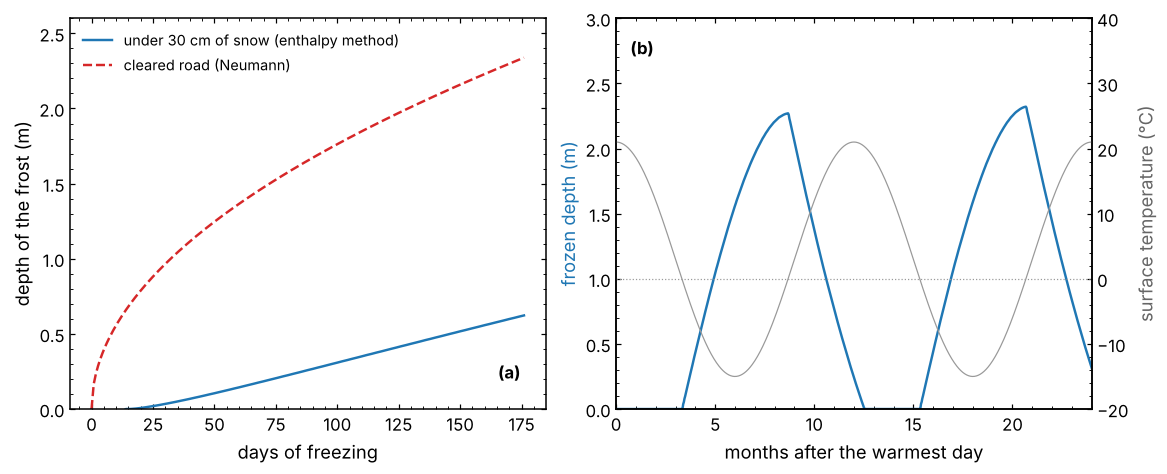

In [4]:
omega = 2 * math.pi / YEAR
dx = 0.04
faces = np.arange(0.0, 15.0 + dx / 2, dx)
t_save = np.linspace(0.0, 2 * YEAR, 731)
seasons = reference.enthalpy_1d_fv(faces, k_f, C_f, k_u, C_u, L_v, 0.0, 3.0, 2 * YEAR,
                                   left=("temperature", lambda t: 3.0 + 18.0 * math.cos(omega * t)),
                                   t_save=t_save)
second = t_save >= YEAR
i_max = int(np.argmax(np.where(second, seasons["front"], 0.0)))
alpha_u = k_u / C_u
d_damp = math.sqrt(2 * alpha_u / omega)
print(f"deepest frost in the second year: {seasons['front'][i_max]:.2f} m,"
      f" {t_save[i_max] / DAY - 365.25 - 182.6:.0f} days after the coldest day at the surface")
print(f"Eq. (6.4) without latent heat: 0 C reaches {d_damp * math.log(18 / 3):.2f} m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax1.plot(out["t"] / DAY, X_fv, "C0", label="under 30 cm of snow (enthalpy method)")
days = np.linspace(0, 176, 200)
ax1.plot(days, no_snow["front"](days * DAY), "C3--", label="cleared road (Neumann)")
ax1.set_xlabel("days of freezing")
ax1.set_ylabel("depth of the frost (m)")
ax1.set_ylim(0, 2.6)
ax1.legend(loc="upper left")
panel_label(ax1, "(a)", x=0.9, y=0.12)

ax2.plot(t_save / DAY / 30.44, seasons["front"], "C0")
ax2.set_xlabel("months after the warmest day")
ax2.set_ylabel("frozen depth (m)", color="C0")
ax2.set_xlim(0, 24)
ax2.set_ylim(0, 3)
ax2r = ax2.twinx()
ax2r.plot(t_save / DAY / 30.44, 3.0 + 18.0 * np.cos(omega * t_save), "0.6", lw=0.8)
ax2r.axhline(0, color="0.6", lw=0.8, ls=":")
ax2r.set_ylabel("surface temperature (°C)", color="0.4")
ax2r.set_ylim(-20, 40)
panel_label(ax2, "(b)")
plt.show()

**Figure S6.1.** (a) Depth of the frost under 30 cm of snow, from the enthalpy method,
and under the cleared road of Section 6.4. (b) The frozen depth through two years of the
seasonal surface temperature (grey, right axis), with the latent heat of the soil water.

The frost reaches 2.32 m in the second winter, about three months after the coldest day at
the surface; the soil above it is then already thawing from the top. Without latent heat,
Eq. (6.4) put the 0 °C isotherm at 4.6 m, twice as deep. A water main 2.5–3 m deep is safe
in this soil without snow; under a snowy lawn it could be much shallower. Real codes give
the depth of seasonal freezing from long records, and add a margin for dry soil, which has
less water to freeze and so freezes deeper.

## Exercise 4. Stefan's formula

With $T_i = T_f$ the second term of Eq. (6.7) vanishes. Writing
$\mathrm{Ste} = C_f(T_f - T_s)/L_v$ and $\alpha_f = k_f/C_f$, what remains is
$\lambda e^{\lambda^2}\mathrm{erf}\lambda = \mathrm{Ste}/\sqrt\pi$. For small $\lambda$,
$e^{\lambda^2} \approx 1$ and $\mathrm{erf}\lambda \approx 2\lambda/\sqrt\pi$, so
$\lambda^2 \approx \mathrm{Ste}/2$ and $X = 2\lambda\sqrt{\alpha_f t} \approx
\sqrt{2\,\mathrm{Ste}\,\alpha_f t} = \sqrt{2k_f(T_f - T_s)t/L_v}$, which is Eq. (6.6).

In [5]:
ratio = lambda Ste: math.sqrt(Ste / 2) / transient.stefan_melting_root(Ste)
for Ste in (0.05, 0.1, 0.2, 0.5, 1.0):
    print(f"Ste = {Ste:4.2f}: Stefan's formula / exact = {ratio(Ste):.3f}")
Ste_5 = brentq(lambda s: ratio(s) - 1.05, 0.01, 2.0)
print(f"within 5 % for Ste < {Ste_5:.2f}; the soil of Section 6.4 has Ste = {C_f * 10 / L_v:.2f}")

Ste = 0.05: Stefan's formula / exact = 1.008
Ste = 0.10: Stefan's formula / exact = 1.016
Ste = 0.20: Stefan's formula / exact = 1.032
Ste = 0.50: Stefan's formula / exact = 1.076
Ste = 1.00: Stefan's formula / exact = 1.140
within 5 % for Ste < 0.32; the soil of Section 6.4 has Ste = 0.22


Stefan's formula is always too large, because it lets all the heat removed go into
freezing and none into cooling the frozen layer. It is within 5 % for Ste below 0.32. The
soil of Section 6.4 has Ste = 0.22, so for soil that starts at 0 °C the formula would be
good to 3 %; the 18 % found in Section 6.4 came from the warm ground below the front, which
Stefan's formula leaves out.